In [1]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import kagglehub
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_class_weight

BASE = kagglehub.dataset_download("kmader/skin-cancer-mnist-ham10000")
df = pd.read_csv(f"{BASE}/HAM10000_metadata.csv")

paths = {}
for part in ["HAM10000_images_part_1", "HAM10000_images_part_2"]:
    d = f"{BASE}/{part}"
    for f in os.listdir(d):
        paths[f.replace(".jpg", "")] = f"{d}/{f}"
df["path"] = df["image_id"].map(paths)

def split(data, n_splits, seed=42):
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    rest, part = next(sgkf.split(data, data["dx"], groups=data["lesion_id"]))
    return data.iloc[rest], data.iloc[part]

train_val, test = split(df, 10)
train, val = split(train_val, 9)
print(len(train), len(val), len(test))

CLASSES = sorted(df["dx"].unique())
label_to_idx = {c: i for i, c in enumerate(CLASSES)}
IMG_SIZE = 128
BATCH = 32

def make_ds(data, training):
    x = data["path"].values
    y = data["dx"].map(label_to_idx).values
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if training:
        ds = ds.shuffle(len(data), seed=42)

    def load(path, label):
        img = tf.io.read_file(path)
        img = tf.image.decode_jpeg(img, channels=3)
        img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
        return img, label

    ds = ds.map(load, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(train, True)
val_ds = make_ds(val, False)
test_ds = make_ds(test, False)

weights = compute_class_weight(
    "balanced", classes=np.arange(len(CLASSES)), y=train["dx"].map(label_to_idx)
)
class_weight = {i: float(np.sqrt(w)) for i, w in enumerate(weights)}
print({CLASSES[i]: round(w, 2) for i, w in class_weight.items()})
print(tf.config.list_physical_devices("GPU"))

Using Colab cache for faster access to the 'skin-cancer-mnist-ham10000' dataset.
8013 1010 992
{'akiec': 2.17, 'bcc': 1.7, 'bkl': 1.14, 'df': 3.49, 'mel': 1.14, 'nv': 0.46, 'vasc': 3.11}
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
from tensorflow import keras
from tensorflow.keras import layers

augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="augmentation")

base = keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights="imagenet"
)
base.trainable = False

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = augmentation(inputs)
x = layers.Rescaling(1.0 / 127.5, offset=-1)(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(CLASSES), activation="softmax")(x)

model = keras.Model(inputs, outputs, name="mobilenetv2_tl")
model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
print("Trainable:", sum(np.prod(w.shape) for w in model.trainable_weights))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Trainable: 8967


In [3]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    class_weight=class_weight,
    callbacks=callbacks,
)

Epoch 1/20
251/251 ━━━━━━━━━━━━━━━━━━━━ 75s 259ms/step - accuracy: 0.6023 - loss: 1.2212 - val_accuracy: 0.6703 - val_loss: 0.8587 - learning_rate: 0.0010
Epoch 2/20
251/251 ━━━━━━━━━━━━━━━━━━━━ 42s 166ms/step - accuracy: 0.6707 - loss: 0.9391 - val_accuracy: 0.7277 - val_loss: 0.7827 - learning_rate: 0.0010
Epoch 3/20
251/251 ━━━━━━━━━━━━━━━━━━━━ 44s 175ms/step - accuracy: 0.6831 - loss: 0.8622 - val_accuracy: 0.7178 - val_loss: 0.8201 - learning_rate: 0.0010
Epoch 4/20
251/251 ━━━━━━━━━━━━━━━━━━━━ 41s 163ms/step - accuracy: 0.6960 - loss: 0.8316 - val_accuracy: 0.6515 - val_loss: 0.9459 - learning_rate: 0.0010
Epoch 5/20
251/251 ━━━━━━━━━━━━━━━━━━━━ 41s 162ms/step - accuracy: 0.7165 - loss: 0.7790 - val_accuracy: 0.6990 - val_loss: 0.8455 - learning_rate: 5.0000e-04
Epoch 6/20
251/251 ━━━━━━━━━━━━━━━━━━━━ 42s 166ms/step - accuracy: 0.7249 - loss: 0.7563 - val_accuracy: 0.6911 - val_loss: 0.8629 - learning_rate: 5.0000e-04
Epoch 7/20
251/251 ━━━━━━━━━━━━━━━━━━━━ 83s 171ms/step - accur

32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 179ms/step
              precision    recall  f1-score   support

       akiec      0.556     0.222     0.317        45
         bcc      0.524     0.660     0.584        50
         bkl      0.475     0.487     0.481       117
          df      0.250     0.091     0.133        11
         mel      0.400     0.347     0.372       121
          nv      0.856     0.887     0.871       657
        vasc      0.474     1.000     0.643         9

    accuracy                          0.728      1010
   macro avg      0.505     0.528     0.486      1010
weighted avg      0.717     0.728     0.717      1010



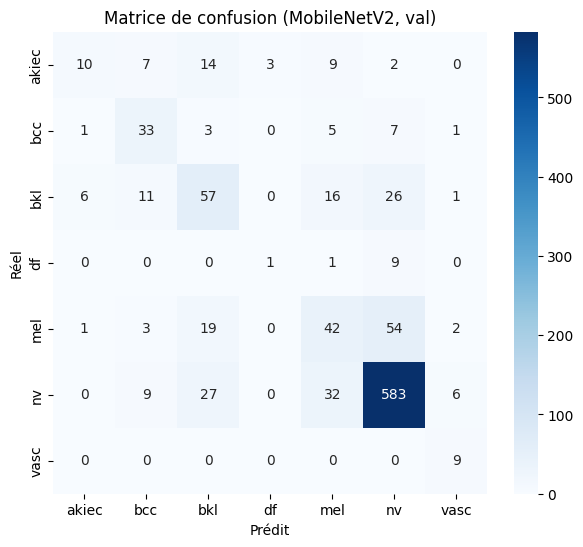

In [4]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

y_true = np.concatenate([y.numpy() for _, y in val_ds])
y_pred = np.argmax(model.predict(val_ds), axis=1)

print(classification_report(y_true, y_pred, target_names=CLASSES, digits=3, zero_division=0))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.title("Matrice de confusion (MobileNetV2, val)")
plt.show()

In [5]:
model.save("mobilenetv2_tl.keras")

from google.colab import files
files.download("mobilenetv2_tl.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>